# Eksperimen Konfigurasi CNN pada Fashion-MNIST

**Nama Kelompok : Kelompok Berkah**<br>
**Nama Anggota :** <br>
**Putra Alfa Juliano Bunga 672024212**<br>
**Nathan Elden Mandeij 672024221**<br>
**Kristopher Sardo Sihotang 672024234**<br>

| Run | Tema | Perubahan dari baseline |
|---|---|---|
| v1 | Baseline | Tidak ada (sama seperti model asli) |
| v2 | Kapasitas model | Filter conv lebih besar + 1 blok conv tambahan, BatchNormalization, Dense neuron dinaikkan |
| v3 | Dinamika training | Dropout diturunkan, optimizer diganti RMSprop dengan learning rate lebih kecil |
| v4 | Kombinasi + detail | Gabungan arsitektur v2 & regularisasi v3, ditambah batch size lebih kecil, epoch lebih banyak, activation ELU |

Setiap skenario dilatih dan dievaluasi secara terpisah, lalu hasilnya dibandingkan di akhir.

In [1]:
#import library
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


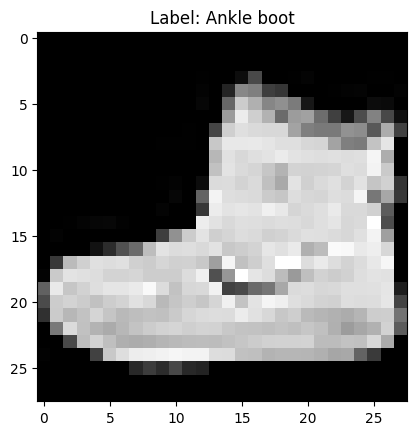

In [2]:
# Memuat data Fashion-MNIST
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

x_train = x_train.reshape(x_train.shape[0], 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1).astype('float32') / 255.0

y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

plt.imshow(x_train[0].reshape(28, 28), cmap='gray')
plt.title(f"Label: {class_names[np.argmax(y_train[0])]}")
plt.show()

## Fungsi bantu untuk menjalankan satu eksperimen

Fungsi `run_experiment` menerima model, konfigurasi training (batch size, epoch), lalu mengembalikan `history` dan `test_acc` supaya mudah dibandingkan.

In [3]:
results = {}

def run_experiment(name, model, batch_size=128, epochs=10):
    print(f"\n===== Menjalankan {name} =====")
    model.summary()
    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(x_test, y_test),
        verbose=2
    )
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"{name} - Akurasi uji: {test_acc*100:.2f}%")
    results[name] = {
        'history': history.history,
        'test_acc': test_acc,
        'test_loss': test_loss,
        'epochs': epochs,
        'batch_size': batch_size
    }
    return history, test_acc

## Run v1 — Baseline

Sama persis dengan model asli. Ini jadi acuan pembanding untuk v2, v3, v4.

In [4]:
def build_model_v1():
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_v1 = build_model_v1()
run_experiment('v1_baseline', model_v1, batch_size=128, epochs=10)


===== Menjalankan v1_baseline =====


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 51s - 108ms/step - accuracy: 0.7604 - loss: 0.6596 - val_accuracy: 0.8452 - val_loss: 0.4258
Epoch 2/10
469/469 - 80s - 171ms/step - accuracy: 0.8452 - loss: 0.4326 - val_accuracy: 0.8639 - val_loss: 0.3723
Epoch 3/10
469/469 - 47s - 99ms/step - accuracy: 0.8641 - loss: 0.3806 - val_accuracy: 0.8779 - val_loss: 0.3351
Epoch 4/10
469/469 - 83s - 176ms/step - accuracy: 0.8739 - loss: 0.3475 - val_accuracy: 0.8881 - val_loss: 0.3094
Epoch 5/10
469/469 - 81s - 172ms/step - accuracy: 0.8852 - loss: 0.3221 - val_accuracy: 0.8939 - val_loss: 0.2942
Epoch 6/10
469/469 - 82s - 175ms/step - accuracy: 0.8906 - loss: 0.3037 - val_accuracy: 0.8960 - val_loss: 0.2881
Epoch 7/10
469/469 - 83s - 177ms/step - accuracy: 0.8944 - loss: 0.2901 - val_accuracy: 0.8988 - val_loss: 0.2781
Epoch 8/10
469/469 - 46s - 98ms/step - accuracy: 0.9009 - loss: 0.2711 - val_accuracy: 0.8994 - val_loss: 0.2732
Epoch 9/10
469/469 - 83s - 177ms/step - accuracy: 0.9047 - loss: 0.2592 - val_accuracy: 0.

(<keras.src.callbacks.history.History at 0x79d3d9ae0830>, 0.904699981212616)

## Run v2 — Kapasitas model lebih besar

Perubahan: filter Conv2D dinaikkan (32→64→128, tambah 1 blok conv), `BatchNormalization()` setelah tiap Conv2D, Dense neuron dinaikkan ke 256. Optimizer, dropout, batch size, epoch, activation tetap sama seperti baseline supaya efek kapasitas model terlihat jelas.

In [5]:
def build_model_v2():
    model = Sequential([
        Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),

        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_v2 = build_model_v2()
run_experiment('v2_kapasitas', model_v2, batch_size=128, epochs=10)


===== Menjalankan v2_kapasitas =====


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 5, 5, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,045,386 (3.99 MB)

 Trainable params: 1,044,746 (3.99 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/10
469/469 - 235s - 502ms/step - accuracy: 0.8311 - loss: 0.4784 - val_accuracy: 0.7821 - val_loss: 0.6872
Epoch 2/10
469/469 - 250s - 534ms/step - accuracy: 0.8862 - loss: 0.3155 - val_accuracy: 0.8769 - val_loss: 0.3209
Epoch 3/10
469/469 - 222s - 472ms/step - accuracy: 0.9028 - loss: 0.2680 - val_accuracy: 0.8954 - val_loss: 0.2710
Epoch 4/10
469/469 - 223s - 475ms/step - accuracy: 0.9146 - loss: 0.2324 - val_accuracy: 0.9015 - val_loss: 0.2740
Epoch 5/10
469/469 - 223s - 475ms/step - accuracy: 0.9239 - loss: 0.2053 - val_accuracy: 0.9103 - val_loss: 0.2562
Epoch 6/10
469/469 - 225s - 480ms/step - accuracy: 0.9298 - loss: 0.1883 - val_accuracy: 0.9142 - val_loss: 0.2659
Epoch 7/10
469/469 - 224s - 478ms/step - accuracy: 0.9354 - loss: 0.1721 - val_accuracy: 0.9120 - val_loss: 0.2693
Epoch 8/10
469/469 - 260s - 553ms/step - accuracy: 0.9413 - loss: 0.1561 - val_accuracy: 0.8970 - val_loss: 0.3637
Epoch 9/10
469/469 - 223s - 475ms/step - accuracy: 0.9463 - loss: 0.1421 - val_a

(<keras.src.callbacks.history.History at 0x79d3d9a02ad0>, 0.9002000093460083)

## Run v3 — Dinamika training (regularisasi & optimizer)

Perubahan: dropout diturunkan ke 0.3, optimizer diganti RMSprop dengan learning rate lebih kecil (0.0001). Arsitektur conv/dense tetap sama seperti baseline supaya efek training dynamics terlihat jelas, terpisah dari efek ukuran model.

In [6]:
def build_model_v3():
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer=RMSprop(learning_rate=0.0001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_v3 = build_model_v3()
run_experiment('v3_training_dynamics', model_v3, batch_size=128, epochs=5)


===== Menjalankan v3_training_dynamics =====


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
469/469 - 51s - 109ms/step - accuracy: 0.6042 - loss: 1.1508 - val_accuracy: 0.7510 - val_loss: 0.7003
Epoch 2/5
469/469 - 49s - 103ms/step - accuracy: 0.7490 - loss: 0.6805 - val_accuracy: 0.7892 - val_loss: 0.5839
Epoch 3/5
469/469 - 80s - 171ms/step - accuracy: 0.7884 - loss: 0.5794 - val_accuracy: 0.8125 - val_loss: 0.5183
Epoch 4/5
469/469 - 48s - 101ms/step - accuracy: 0.8094 - loss: 0.5249 - val_accuracy: 0.8223 - val_loss: 0.4917
Epoch 5/5
469/469 - 49s - 104ms/step - accuracy: 0.8232 - loss: 0.4894 - val_accuracy: 0.8350 - val_loss: 0.4544
v3_training_dynamics - Akurasi uji: 83.50%


(<keras.src.callbacks.history.History at 0x79d3d87f9d10>, 0.8349999785423279)

## Run v4 — Kombinasi terbaik + penyempurnaan detail

Menggabungkan arsitektur v2 (kapasitas) dengan regularisasi v3 (dropout 0.3, RMSprop lr kecil), lalu menambahkan penyempurna: batch size lebih kecil (64), epoch lebih banyak (15), activation ELU sebagai pengganti ReLU.

In [7]:
def build_model_v4():
    act = 'elu'
    model = Sequential([
        Conv2D(64, (3, 3), activation=act, input_shape=(28, 28, 1)),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation=act),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation=act, padding='same'),
        BatchNormalization(),

        Flatten(),
        Dense(256, activation=act),
        Dropout(0.3),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer=RMSprop(learning_rate=0.0001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_v4 = build_model_v4()
run_experiment('v4_kombinasi', model_v4, batch_size=128, epochs=8)


===== Menjalankan v4_kombinasi =====


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 11, 11, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 5, 5, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,045,386 (3.99 MB)

 Trainable params: 1,044,746 (3.99 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/8
469/469 - 250s - 534ms/step - accuracy: 0.8256 - loss: 0.5086 - val_accuracy: 0.7598 - val_loss: 0.6518
Epoch 2/8
469/469 - 250s - 532ms/step - accuracy: 0.8804 - loss: 0.3398 - val_accuracy: 0.8845 - val_loss: 0.3199
Epoch 3/8
469/469 - 264s - 564ms/step - accuracy: 0.8964 - loss: 0.2881 - val_accuracy: 0.8986 - val_loss: 0.2869
Epoch 4/8
469/469 - 239s - 509ms/step - accuracy: 0.9085 - loss: 0.2523 - val_accuracy: 0.8925 - val_loss: 0.3021
Epoch 5/8
469/469 - 240s - 511ms/step - accuracy: 0.9185 - loss: 0.2237 - val_accuracy: 0.8895 - val_loss: 0.3097
Epoch 6/8
469/469 - 242s - 516ms/step - accuracy: 0.9263 - loss: 0.2000 - val_accuracy: 0.9060 - val_loss: 0.2671
Epoch 7/8
469/469 - 238s - 508ms/step - accuracy: 0.9342 - loss: 0.1786 - val_accuracy: 0.9090 - val_loss: 0.2657
Epoch 8/8
469/469 - 237s - 506ms/step - accuracy: 0.9423 - loss: 0.1594 - val_accuracy: 0.9066 - val_loss: 0.2775
v4_kombinasi - Akurasi uji: 90.66%


(<keras.src.callbacks.history.History at 0x79d3d9a76ea0>, 0.9065999984741211)

## Perbandingan hasil keempat skenario

Skenario              Test Acc    Test Loss   Epoch   Batch   
v1_baseline           90.47       0.2632      10      128     
v2_kapasitas          90.02       0.3162      10      128     
v3_training_dynamics  83.50       0.4544      5       128     
v4_kombinasi          90.66       0.2775      8       128     


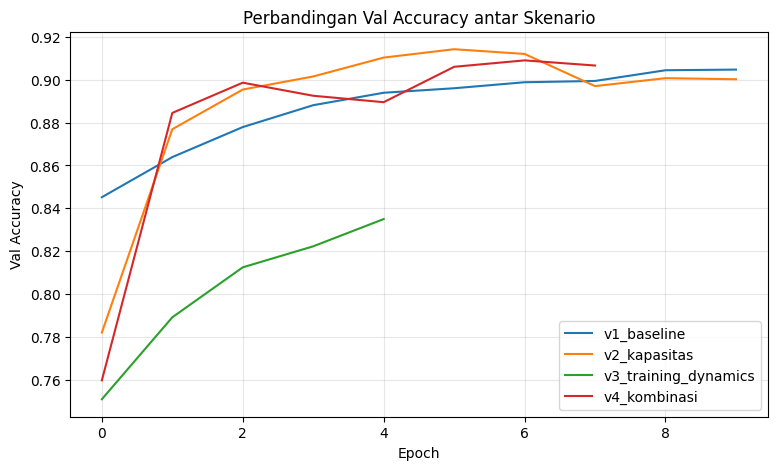

In [8]:
print(f"{'Skenario':<22}{'Test Acc':<12}{'Test Loss':<12}{'Epoch':<8}{'Batch':<8}")
for name, r in results.items():
    print(f"{name:<22}{r['test_acc']*100:<12.2f}{r['test_loss']:<12.4f}{r['epochs']:<8}{r['batch_size']:<8}")

# Grafik perbandingan val_accuracy antar skenario
plt.figure(figsize=(9, 5))
for name, r in results.items():
    plt.plot(r['history']['val_accuracy'], label=name)
plt.title('Perbandingan Val Accuracy antar Skenario')
plt.xlabel('Epoch')
plt.ylabel('Val Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()